# 1. Business Understanding - Identifying business needs

## Context
Everything & Then Some, Ltd. is a diversified wholesale company that supplies business and specialist retailers across tools and hardware, lighting, automotive care, household goods and other product lines. Its customers buy in very different patterns, so the sales team cannot tell by eye which accounts are drifting away.

## Problem:
Today, the company finds out a customer has stopped buying only after the orders stop. By then, a follow-up is late and costly. The commercial team needs an early signal at the moment of each purchase. 

## Business question:
Will this customer make another purchase within 90 days after the current transaction?

## Objective:
Build a binary classifier that scores every purchase occasion with the probability of a repeat purchase within 90 days. Customers with a low score are flagged for a targeted action such as a call, an account review or an offer. Customers with a high score are left alone, so sales effort goes where it most likely to retain revenue

## Decision support:
After each purchase, decide whether to intervene with this customer

## Data available at decision time:
- Current transaction values and categories
- Purchase history (recency, tenure, prior spend and gaps)
- Rolling purchase counts and spend over 30, 90, 180 and 365 days
- Optional customer attributes

- Nothing recorded after the purchase date may be used


## <span style="color:#c0392b">Cost of errors</span>
- A false alarm (flagging customer who would have returned) wastes a call or a discount
- A miss (not flagging a customer who leaves) loses future margin. The average payable amount per purchase is about 926.
- Misses are likely costlier, but the ratio is not given, so the report will show how chosen cutoff changes with it.

## <span style="color:#1e8449">Success criteria</span>
- The model must clearly beat two baseline: always predicting a repeat (56% accuracy) and a one-rule recency model (66% accuracy, ROC-AUC 0.68).
- Performance is judged many by ROC-AUC, supported by precision and recall on the no-repeat class.
- REsults are validated on later purchases, since the production data comes after the training period.

## Scope and limits:
The model predicts behaviour. It does not explain why customers leave, and it does not decide the recommended action. Those remain business decisions. 

## Variable definitions

This brief describes the variables in groups. We asume the Portuguese invoice fields from their names and confirm them with accounting identities: gross discounts = net and net + tax = total pay hold in every row. Several monetary columns are therefor near-duplicates, which we look further into in feature selection.

### Identifiers and target
- ID: row number, also used as the Kaggle key
- customer_id: Anonymised customer number: join key for clientes.csv
- repeat_purchase _90d: boolean (1 = buy again within 90d, 0 = no buy within 90d)
- purchase_date: anonymised date; order and gaps are real

### Current purchase: money (Portuguese invoice fields)
- Total_Bruto: Gross amount before discounts
- Total_Desclinha: Discounts on individual invoice line
- Total_Desc_Global: Discount on the whole invoice
- Total_Liquido: Net amount after discounts, before tax
- Total_Imp: TAX (Vat; "imposto")
- Total_a_pagar: Final amount the customer pays (net + tax)
- Total_Portes: Shipping cost
- Custo: Cost of the goods to the company

### Current purchase: details
- N_detalhes: Number of line items on the order
- invoice_count_current_purchase: Invoices issued for this purchase occasion
- payment_type: Payment terms or method (9 levels)
- salesperson; Sales rep handling the order (9 person)
- commercial_zone: sales territory (5 zones)
- transport_method: Delivery method or route (80 levels)
- warehouse: shipping warehouse (2 levels)
- document_series; invoice series or type (e,g, different billing channels (3))

### Customer history before this purchase
- Days_since_previous_purchase: Recency - days since the customer's last purchase
- customer_tenure_days: Days since the customer's first purchase
- prior_purchase_count: Number of earlier purchases
- prior_mean_gap_days / prior_std_gap_days: average and spread of days between earlier purchases
- prior_total_spend: Total spent on earlier purchases
- prior_mean/std/min/max_purchase_value: Summary of earlier order values

# 2. Data understanding - Data Exploration

## 2.1 Import all librariess needed for this section

In [1]:
# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics 
from scipy import stats
from scipy.stats import pearsonr, spearmanr, chi2_contingency

# Preprocessing
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Feature selection
from sklearn.inspection import permutation_importance

# Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import (roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Optional
sns.set_theme(style="whitegrid")
DATA_DIR = "../data/" # Folder with the data files: can be changed if the folder header is named different. 
RANDOM_STATE = 42 # Fixed random seed, so results are the same on every run.

## 2.2 Load, check and explore the data

### 2.2.1 Load dataset

In [2]:
train = pd.read_csv(DATA_DIR + "train.csv", parse_dates=["purchase_date"]) # Parse_date turns the text date into a datetine
test = pd.read_csv(DATA_DIR + "test.csv", parse_dates=["purchase_date"]) 
clientes = pd.read_csv(DATA_DIR + "clientes.csv")                          # Customer table
sample_submission = pd.read_csv(DATA_DIR + "sample_submission.csv")        # the format kaggle expects - uses the same column header, so it avoids spelling mistakes

ID_COL, TARGET = sample_submission.columns                                 # Takes the two column names from the sample_submission instead of manually typing them (risks of spelling errors)
CUST_COL = "customer_id"                                                   # customer key, stored once to avoid typo errors
DATE = "purchase_date"                                                     # Date column, stored once

print("train:", train.shape, "| test:", test.shape, "| clientes:", clientes.shape) # Shows rows, columns of each tables
train.head()                                                               # Shows first 5 rows
                                

train: (6534, 39) | test: (986, 38) | clientes: (1143, 13)


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


### 2.2.2 Explore the datasets

In [3]:
# list all the non-numerical columns
print(train.select_dtypes(exclude="number").columns.tolist())

print(train.dtypes)

['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'purchase_date']
Total a Pagar                            float64
Total Bruto                              float64
Total Liquido                            float64
Total Imp_                               float64
Total Portes                             float64
Total Desc_ Global                       float64
Total Desc_ Linha                        float64
Custo                                    float64
N_ Detalhes                              float64
invoice_count_current_purchase           float64
repeat_purchase_90d                        int64
days_since_previous_purchase             float64
customer_tenure_days                     float64
prior_purchase_count                     float64
prior_total_spend                        float64
prior_mean_purchase_value                float64
prior_std_purchase_value                 float64
prior_min_purchase_value                 float6

In [4]:
# Split the predictors into categorical and numerical

CAT_COLS = ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series']
NUM_COLS = [c for c in train.columns
            if c not in CAT_COLS + [ID_COL, TARGET, CUST_COL, DATE]] # includes everything exept categoricals in CAT_COL, IDs, Target and dates

# print count of numeric and categorical variables
print(len(NUM_COLS), "numeric and", len(CAT_COLS), "Categorical predictors")

# Show plain numbers with 2 decimal instad of 1.0e+09 in max values
pd.set_option("display.float_format", "{:.2f}".format)

num_summary = train[NUM_COLS].describe().T # Descriptive statistics
num_summary["missing_%"] = train[NUM_COLS].isna().mean()*100 # share of empty values per variables
num_summary.sort_values("missing_%", ascending=False) # Sort the list based on missing %

29 numeric and 6 Categorical predictors


,count,mean,std,min,25%,50%,75%,max,missing_%
prior_std_gap_days,5056.00,74.14,101.82,0.00,32.74,50.64,78.63,2212.54,22.62
prior_mean_gap_days,5226.00,95.88,122.59,-4.00,42.60,68.44,113.83,3199.00,20.02
prior_std_purchase_value,5421.00,737.47,666.26,0.00,258.56,569.08,981.09,6770.22,17.03
prior_mean_purchase_value,5672.00,2821825.32,53041566.66,-2478.66,359.56,724.90,1095.89,1000000000.00,13.19
days_since_previous_purchase,5673.00,101.53,165.70,-4.00,17.00,57.00,119.00,3199.00,13.18
prior_min_purchase_value,5866.00,185.46,408.40,0.93,15.45,64.34,162.61,6298.98,10.22
prior_max_purchase_value,5866.00,2946.38,5901.55,3.31,834.53,1783.24,3504.42,267526.19,10.22
spend_365d,6274.00,2396534.88,48841133.46,-159115.18,637.78,2426.61,7045.42,1000000000.00,3.98
Total Portes,6469.00,1.15,5.84,0.00,0.00,0.00,0.00,181.06,0.99
Total Bruto,6469.00,886.15,1327.64,0.83,175.74,445.74,1036.70,21578.28,0.99


In [5]:
# count, unique levels, most frequent, top % and missing %
cat_summary = train[CAT_COLS].describe().T

# Share of the most frequent level among the non-missing rows
cat_summary["top_share_%"] = (cat_summary["freq"] / cat_summary["count"] * 100).astype(float).round(1)

# Sare of ows where the value is still missing
cat_summary["missing_%"] = (train[CAT_COLS].isna().mean() *100).round(1)

cat_summary

,count,unique,top,freq,top_share_%,missing_%
payment_type,6274,9,Maybe Tomorrow Payment 7,4565,72.80,4.00
salesperson,6275,9,VLOOKUP Master 1,4054,64.60,4.00
commercial_zone,6469,5,Decorative Dashboard Zone 4,6260,96.80,1.00
transport_method,6273,80,Maybe Tomorrow Delivery 72,1119,17.80,4.00
warehouse,6274,2,Final Excel Warehouse 1,6253,99.70,4.00
document_series,6469,3,Ctrl Z Series 2,2738,42.30,1.00


## 2.3 Target balance, date ranges, customers

This step decides validation split and whether customer_id can be feature.

In [6]:
# Class balance: Share of 0s and 1s in the taget
print("Target share:\n", train[TARGET].value_counts(normalize=True).round(3))

# Date ranges: is test later than train?
print("\nTrain dates:", train[DATE].min().date(), "to", train[DATE].max().date())
print("Test dates: ", test[DATE].min().date(), "to", test[DATE].max().date())

# Customers: how often does the same customer appear?
rows_per_customer = train.groupby(CUST_COL).size() # Number of rows per customer
print("\nCustomers in train:", rows_per_customer.size,
      "| median rows per customer:", rows_per_customer.median(),
      "| max:", rows_per_customer.max())
print("Test customers already seen in train:",
      round(test[CUST_COL].isin(train[CUST_COL]).mean(),3)) # Share of test rows whose customer is also in train set

Target share:
 repeat_purchase_90d
1   0.56
0   0.44
Name: proportion, dtype: float64

Train dates: 2015-07-11 to 2025-02-15
Test dates:  2025-05-24 to 2026-10-06

Customers in train: 610 | median rows per customer: 4.0 | max: 277
Test customers already seen in train: 0.945


This shows that the target is only mildly imbalanced (56/44), so I keep all rows and use ROC-AUC as the main metric. It also shows that the test is strictly later than train, so I validate on the most recent part o the train instead of a random split. 
    
94.5% of test rows belong to customers already seen in train, su customer history is available for almost all predictions. 
The model could learn that "customer xxxxxx usually repeats" instead of learning behavious. This can risk overfitting to identities (memorisation doesn't generalise)


## 2.4 Data quality: blank rows and weird values

In [7]:
# Fully blank rows: every feature empty (ID, customer_id and target are still filled)
feature_cols = NUM_COLS + CAT_COLS + [DATE]
blank_rows = train [feature_cols].isna().all(axis=1) # true if every feature in the row is empty
print("Fully blank rows:", blank_rows.sum(), "(train) |",
      test[feature_cols].isna().all(axis=1).sum(), "(test)")

# Impossible values: negative days/amounts and weird placeholders (100000000 values etc)
NON_NEGATIVE = ["days_since_previous_purchase", 
                "prior_mean_purchase_value",
                "prior_mean_gap_days", 
                "spend_365d"]

impossible = pd.DataFrame({
    "negative_train": (train[NON_NEGATIVE] < 0).sum(), # days and money cannot be negative
    "placeholder_train": (train[NON_NEGATIVE] >=1e9).sum(), # 1e9 = 1.000.000.000, not a real ammount
    "negative_test": (test[NON_NEGATIVE] < 0).sum(), 
    "placeholder_test": (test[NON_NEGATIVE] >= 1e9).sum(),
})

impossible

Fully blank rows: 65 (train) | 0 (test)


,negative_train,placeholder_train,negative_test,placeholder_test
days_since_previous_purchase,16,0,2,0
prior_mean_purchase_value,16,16,2,2
prior_mean_gap_days,16,0,2,0
spend_365d,15,15,2,2


Why the blank check only look at the feature column: the 65 blank rows found still have an ID column, a customer_id and a target (not blank). A check over all columns would find 0 blank rows and miss these.

In the table, we can see that 65 rows with every featuer empty, so I will drop them from the train. Test has none, so no test rows are lost. 

Also, I saw that negative values and a 1e9 placeholder in days and spend columns, in both train and test, so I will set them to missing with one rule applied to both files and let the imputer fill them. (see prior_mean_purchase_value and spend_365d in 2.2.2)

## 2.5 relationships
recency and frequency boxplots against the target, then the correlation heatmap of the rolling features. 

### 2.5.1: Recency and frequency vs target

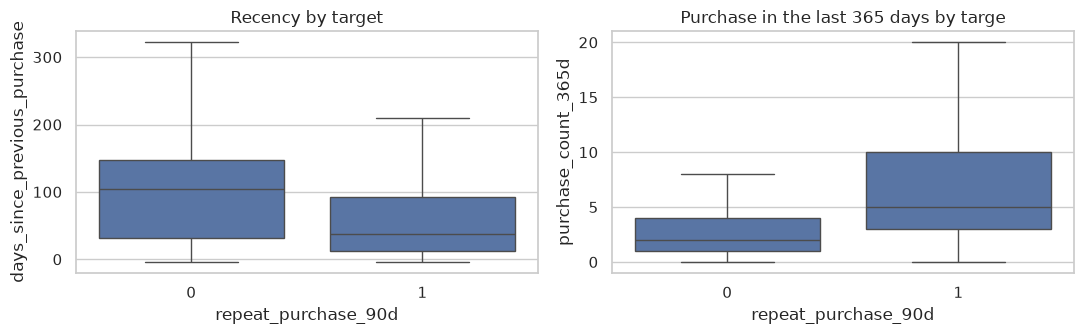

,days_since_previous_purchase,purchase_count_365d
repeat_purchase_90d,,
0,105.00,2.00
1,37.00,5.00


In [8]:
# Do customers who bought recently, or often, come back more?
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

sns.boxplot(data=train, x=TARGET, y="days_since_previous_purchase", ax=axes[0], showfliers=False)
axes[0].set_title("Recency by target")

sns.boxplot(data=train, x=TARGET, y="purchase_count_365d", ax=axes[1], showfliers=False)
axes[1].set_title("Purchase in the last 365 days by targe")

plt.tight_layout()
plt.show()

# The medians behind the boxes, so they can be quoted in the text
train.groupby(TARGET)[["days_since_previous_purchase", "purchase_count_365d"]].median()

"showfliers=False" hides the outliers, including the negative placehoder values, so the boxes stay readable. The 2.4 table already counted those values

Output:
median recency is 105 days for non-repeaters and 37 days for repeaters. Median purchase in the last 365 days are 2 vs 5.

W esaw that repeat buyers bought much more recently and much more often, so the history features carry the main signal and must survive in feature selection.

### 2.5.2: which variables relates to the target

In [9]:
# Spearman correlation of each numeric variables with the target (absolute value, strongest first)
target_corr = (train[NUM_COLS]
    .corrwith(train[TARGET], method="spearman")
    .abs()
    .sort_values(ascending=False)
    .round(3))

target_corr
                        

purchase_count_365d              0.44
prior_mean_gap_days              0.42
purchase_count_180d              0.41
purchase_count_90d               0.39
spend_365d                       0.39
spend_180d                       0.37
spend_90d                        0.36
prior_purchase_count             0.35
prior_total_spend                0.33
prior_std_gap_days               0.32
days_since_previous_purchase     0.31
purchase_count_30d               0.26
prior_max_purchase_value         0.25
spend_30d                        0.24
prior_min_purchase_value         0.23
Total Desc_ Linha                0.20
prior_std_purchase_value         0.17
customer_tenure_days             0.12
prior_mean_purchase_value        0.09
Total Imp_                       0.08
Total Bruto                      0.08
invoice_count_current_purchase   0.06
Total a Pagar                    0.05
Total Liquido                    0.05
Total Desc_ Global               0.04
N_ Detalhes                      0.03
Total Portes

With this we can see that history and rolling features are the most related to the taget, while the current invoice amounts barely relate to it, and random_noise shows essentially no relationship, as a pure noise column should.

So random_noise is a useful benchmark: in feature selectin, any feature that does no better than random_noise will be dropped automatically.

### 2.5.3: First purchase vs returning customer

In [10]:
# Repeat rate for first purchases vs customers with earleir pruchases
first_purchase = train["prior_purchase_count"] == 0
train.groupby(first_purchase)[TARGET].mean().round(3).rename(
    index={True: "first purchase", False: "returning customer"})

prior_purchase_count
returning customer   0.58
first purchase       0.33
Name: repeat_purchase_90d, dtype: float64

#### Output:
first purchases repeat 33.3% of the time, against 58.2% for returning customers.

We saw that first-time buyers are less likely to return, and that their history features are empty by definition. So I will add in is_first_purchase flag, which keeps that information after the empty values are imputed.

### 2.5.4: Redundancy between features

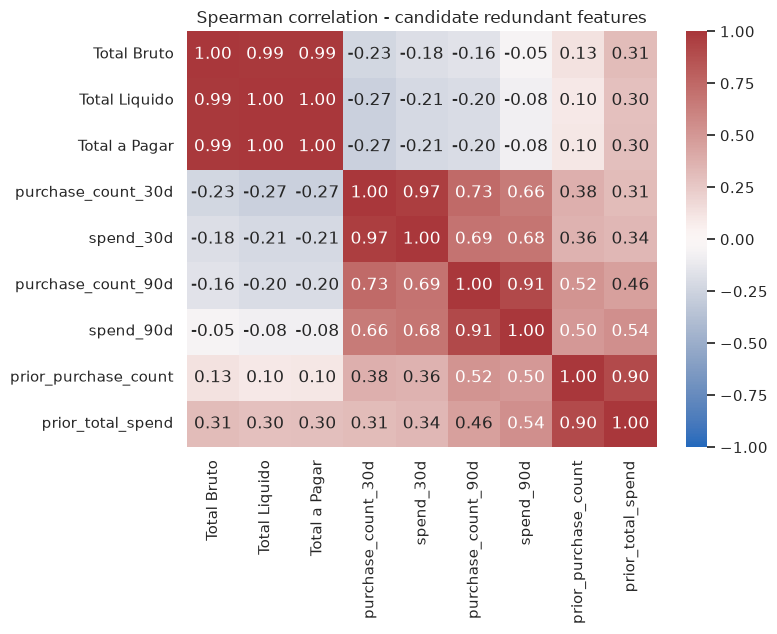

In [11]:
# Columns that are likely to measure the same thin:
REDUNDANCY_CHECK = [
    "Total Bruto", 
    "Total Liquido", 
    "Total a Pagar", 
    "purchase_count_30d",
    "spend_30d",
    "purchase_count_90d", 
    "spend_90d",
    "prior_purchase_count",
    "prior_total_spend"]

plt.figure(figsize=(8, 6.5))
sns.heatmap(train[REDUNDANCY_CHECK].corr(method="spearman"),
            annot=True,
            fmt=".2f",
            cmap="vlag",
            center=0,
            vmin=-1,
            vmax=1) # vmiin/vmax fix the color scale at -1..1

plt.title("Spearman correlation - candidate redundant features")
plt.tight_layout()
plt.show()

#### Output: 

These pairs are above 0.9:
- Total Liquido / total a Pagar
- Total Bruto / Total Liquido and Total a Pagar
- purchase_count_30d / spend_30d
- purchase_count_90d / spend_90d
- prior_purchase_count / prior_total_spend

The three invoice totals are near-copies, which matches the accounting identities: net plus tax equals the amount to pay. Over short windows, count and spend move together

We also saw seneveral near-duplicate above 0.9, so we will remove one featuer from each pair in feature selection, keeping the one more related to the target. Keeping both would add no information and would make Logistic Regression's coefficient unstable.

The categorical concentration table we built earlier also belongs here, were warehouse (99.7%) and commercial zone (97.7%) were almost constants 

## 2.6: Clientes csv check
Deciding whether and how the we can use the clientes.csv to better our model and if it should be integrated

In [12]:
# How complete and how varied is each column in clientes.csv?
clientes_summary = pd.DataFrame({
    "missing_%": (clientes.isna().mean()*100).round(2),  # Share of empty cells
    "unique": clientes.nunique(),                        # number of distinct values
}).sort_values("missing_%", ascending=False)
print(clientes_summary)

# Can every customer be joined?
print("\nTrain customers found in clients:", train[CUST_COL].isin(clientes[CUST_COL]).mean())
print("test customers found in clientes:", test[CUST_COL].isin(clientes[CUST_COL]).mean())

# Temporary copy of trian with the customer's start year joined in
check = train.merge(clientes[[CUST_COL, "customer_since_year"]], on=CUST_COL, how="left")

# Years between becoming a customer and this purchase
check["years_as_customer"]=check[DATE].dt.year - check["customer_since_year"]

print("\nSpearnman correlation with existing tenure:", 
      round(check["years_as_customer"].corr(check["customer_tenure_days"], method="spearman"), 2))
print("Spearman correlation with target - years_as_customer:",
      round(check["years_as_customer"].corr(check[TARGET], method="spearman"), 3),
      "| customer_tenure_days:",
      round(check["customer_tenure_days"].corr(check[TARGET], method="spearman"), 3))

                     missing_%  unique
customer_type           100.00       0
street                   52.32     511
island                   50.57      10
city                     47.77     417
postal_code              14.87     828
municipality             13.91     183
commercial_region         9.97      37
postal_area               6.21     271
address                   0.52    1120
country_or_region         0.00      11
customer_id               0.00    1143
company_name              0.00    1141
customer_since_year       0.00      12

Train customers found in clients: 1.0
test customers found in clientes: 1.0

Spearnman correlation with existing tenure: 0.92
Spearman correlation with target - years_as_customer: 0.108 | customer_tenure_days: 0.12


#### Output:

We can see that clients covers every customer, but its columns are either empty, half missing, identifiers, or too fine-grained (too many levels on categoricals). 

The one complete attribute, customer_since_year is almost identical to tenure feature already in train (Spearman 0.92) and relates less to the target. 

Based on this, we will not join clientes: it would just add redundant information and extra preprocessing without new information or signal. 

# 3. Data preperation - Preprocessing

## 3.1 Cleaning and new features
One function applies every row-level fix and new features. It learns nothing from the data, since each rule uses only the row itself, so applying it to both train and test cannot cause data leakage.

In [13]:
# Columns where a negative value or the 1e9 placeholder is impossible.
NON_NEGATIVE = ["days_since_previous_purchase", 
                "prior_mean_purchase_value", 
                "prior_mean_gap_days",
                "spend_365d"]

# Copy and never change the original dataset
def prepare(df):
    """Row level cleaning and new features. Nothing is learned from the data here."""
    df = df.copy()

    # Impossible values become missing: the imputer fills them later
    for col in NON_NEGATIVE:
        df.loc[(df[col]<0)|(df[col]>=1e9),col]=np.nan

    # New features
    df["is_first_purchase"] = (df["prior_purchase_count"] == 0).astype(int)                                                           # 1 = no early purchases
    df["discount_rate"] = ((df["Total Desc_ Linha"] + df["Total Desc_ Global"]) / df["Total Bruto"])                                  # Share of hte amount discounted
    df["margin_rate"] = (df["Total Liquido"] - df["Custo"]) / df ["Total Liquido"]                                                    # Profit share of the net amount
    df["recency_vs_usual_gap"] = (df["days_since_previous_purchase"] / df["prior_mean_gap_days"]).replace([np.inf, -np.inf], np.nan)  # > 1 = later than usual
    return df

# Drop the full blank rows from train only (test has none, and test rows can never be dropped)
feature_cols = NUM_COLS + CAT_COLS + [DATE]
blank_rows = train[feature_cols].isna().all(axis=1)

train_clean = prepare(train[~blank_rows]) # ~ means "not": keep rows that are not blank
test_clean = prepare(test)

ENGINEERED = ["is_first_purchase", "discount_rate", "margin_rate", "recency_vs_usual_gap"] # The new features from earlier

print("train:", train.shape, "->", train_clean.shape, "| test:", test.shape, "->", test_clean.shape)
print("Impossible values left:", 
      ((train_clean[NON_NEGATIVE] < 0) | (train_clean[NON_NEGATIVE] >= 1e9)).sum().sum())

train_clean[ENGINEERED].corrwith(train_clean[TARGET], method="spearman").round(3)



train: (6534, 39) -> (6469, 43) | test: (986, 38) -> (986, 42)
Impossible values left: 0


is_first_purchase      -0.15
discount_rate           0.22
margin_rate             0.12
recency_vs_usual_gap   -0.06
dtype: float64

#### Output:
- Train goes from (6534,39) to (6469,43): 65 rows dropped and 4 features added. Test goes from (986, 38) to (986, 42), with no rows lost
- Impossible values left 0.
- Correlations with the target: discount_rate (0.22), is_first_purchase (-0,146), margin_rate (0.118) and recency_vs_usual_gap (-0.056)

We saw negative and placeholder values in section 2.4, so they are now set to missing in both files with one rule. 
We also saw that first purchases repeat far less often (33% vs 58%, so is_first_purchase keeps that information after their empty history values are imputed.
The raw invoice amounts barely relate to the target, so we turned them into rates (discount and margin), which describe the deal rather than its size.
recency_vs_usual_gap measures whether a customer is late compare with their own rhythm. Its correlation is weak, so feature selection will decide whether it stays. 

## 3.2 Time-ordered train/validation split

Test contains purchases made after all of train. To mimic that, we validate on the most recent 20% of train and fit on the older 80%. We cut on a date, so purchases from the same day never fall on both sides.

In [14]:
cut_date = train_clean[DATE].quantile(0.8)              # Date that leaves the newest 20% of rows after it
fit_part = train_clean[train_clean[DATE] < cut_date]    # Older purchases: used to fit
val_part = train_clean[train_clean[DATE] >= cut_date]   # Newer purchases: used to validate

print("Cut date:", cut_date.date())
print("fit:", fit_part[DATE].min().date(), "to", fit_part[DATE].max().date(), "|", len(fit_part), "rows")
print("Val:", val_part[DATE].min().date(), "to", val_part[DATE].max().date(), "|", len(val_part), "rows")
print("Repeat rate fit / val:", round(fit_part[TARGET].mean(), 3), "/", round(val_part[TARGET].mean(), 3))

Cut date: 2023-06-17
fit: 2015-07-11 to 2023-06-13 | 5171 rows
Val: 2023-06-17 to 2025-02-15 | 1298 rows
Repeat rate fit / val: 0.549 / 0.603


#### Output:
- Cut date: 2023-06-17 (5,171) goes to fitting (up to 2023-06-13) and 1.298 to vaidation from (2023-06-17).
- The repeat rate is 0.549 in fit and 0.603 in validation

The repeat rate is higher in the recent period (60% vs 55%), so the behaviour drifts over time. That is one more reason to validate on recent data rather than random sample

## 3.3 Preprocessing pipeline
- Numeric columns: median imputation, because the medians are robust to skew distribution, then standard scaling, because Logistic Regression is sensitive to feature scale.
- Categorical columns: missing values become their own "missing" level, then on-hot-encoding. Levels seen fewer than 20 times are grouped into one "infrequent" column, and levels that appear only in test are handled without errors
- the pipeline is fitted on the fit part only. Validation and test data only pass through .transform.


In [15]:
def make_preprocessor(num_cols, cat_cols):
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),      # Fill the gaps with the column median (learned on fit data)
        ("scale", StandardScaler()),                       # Mean 0, standard deviation 0
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),              # Missing = own category
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)), # One 0/1 column per level
    ]) 
    return ColumnTransformer([
        ("num", numeric, num_cols),
        ("Cat", categorical, cat_cols),
    ])

# Check: fit on the fit part ony, then transform the other sets
check_prep = make_preprocessor(NUM_COLS + ENGINEERED, CAT_COLS)
X_fit = check_prep.fit_transform(fit_part)
X_val = check_prep.transform(val_part)
X_test = check_prep.transform(test_clean)

print("Columns after preprocessing:", X_fit.shape[1],
      "| rows fit / val / test:", X_fit.shape[0], X_val.shape[0], X_test.shape[0])

Columns after preprocessing: 89 | rows fit / val / test: 5171 1298 986


#### Output: 
- 89 columns after preprocessing
- The 33 numeric columns stay as they are
- the 6 categoricals expand into one-hot columns
- 31 of them from transport_method alone

This cell is only a check that the pipeline runs and the shapes line up. In section 5 the preprocessor goes inside the model's pipeline, so it's refitted automatically every time the model is fitted. That's what keeps feature selection and validation leakage free.

Why the min_frequency = 20
transport_method has 80 levels. Without grouping we'd get 80 columns, many with only a handful of 1s, wich the model would mostly memorise.

# 4 Feature selection
Drop identifiers and near-constant columns, run the correlation filter, then test each feature against random_noise. 

1. Remove Identifiers and near-constant categoricals
2. Redundancy filter: for numeric pais with | spearman | > 0.9, keep the features more related to the target
3. Noice probe: keep only features that are more useful than random_noise, measured with permutation (how much a model's prediction error increases when a feature's values are randomly shuffled, breaking its relationship with the true outcome) importance.
4. Compare the feature candidate sets and keep the simplest set that performas as well.

## 4.1 Reove Identifiers and near-constant variables

In [16]:
# ID and customer_id were never in NUM_COLS: Warehouse and commercial_zones are nearly constant (2.2.2)
candidate_num = NUM_COLS + ENGINEERED
candidate_cat = [c for c in CAT_COLS if c not in ["warehouse", "commercial_zone"]]
print("Start:", len(candidate_num), "numeric +", len(candidate_cat), "categorical")

Start: 33 numeric + 4 categorical


Output: ID is a row number and customer_id is a customer label. We exclude customer_id because it is an arbitrary label: its numeric value carries no meaning, and keeping it would let the model memorise known customers instead of learning behaviour that applies to new ones. The customer's past behaviour is already represented by the history features, warehouse (99.7% one level) and commercial zone (96.8%) are nearly constant, so they cannot seperate the classes (Section 2.2)

## 4.2 Redundancy filter
Here we are filtering for redundant features and only keeps the features that best correlates to the target via survival of the fittest method.

In [17]:
corr = fit_part[candidate_num].corr(method="spearman").abs()                               # features vs feature
target_corr = fit_part[candidate_num].corrwith(fit_part[TARGET], method="spearman").abs()  # feature vs target

to_drop = set()
dropped_pairs = []                                                                 # One entry per dropped feature, for the table
for i, a in enumerate(candidate_num):                                              # compare every pair once
    for b in candidate_num[i + 1:]:
        if a in to_drop or b in to_drop or "random_noise" in (a, b):
            continue                                                               # skip pairs already handled, and never drop the probe here
        if corr.loc[a, b] > 0.9:
            weaker, kept = (a, b) if target_corr[a] < target_corr[b] else (b, a)   # keep the one more related to the target
            to_drop.add(weaker)
            dropped_pairs.append({
                "kept": kept,
                "dropped": weaker,
                "correlation": round(corr.loc[a, b], 2),
                "kept_vs_target": round(target_corr[kept], 3),
                "dropped_vs_target": round(target_corr[weaker], 3),
            })

after_filter = [c for c in candidate_num if c not in to_drop]
print("Left after filter:", len(after_filter), "numeric")
pd.DataFrame(dropped_pairs)

Left after filter: 26 numeric


,kept,dropped,correlation,kept_vs_target,dropped_vs_target
0,Total Bruto,Total a Pagar,0.99,0.06,0.04
1,Total Bruto,Total Liquido,0.99,0.06,0.04
2,discount_rate,Total Desc_ Linha,0.90,0.21,0.18
3,prior_purchase_count,prior_total_spend,0.91,0.34,0.33
4,prior_max_purchase_value,prior_std_purchase_value,0.92,0.25,0.17
5,purchase_count_30d,spend_30d,0.96,0.27,0.24
6,purchase_count_90d,spend_90d,0.92,0.39,0.36


Output:

These features are nearly identical based on the spearman correlation we did in the earlier proces (2.5), so the "kept" ones are used since it is the feature that correlates best to the target, and those that are dropped are redundant features.

## 4.3 Noise probe with permutation importance

A Random Forest is trained on the older part of the fit data and scored on its most recent part, so the real validation set stays untouched. Permutation importance shuffles one column at a time and measures how ROC-AUC drops. A feature that helps less than random_noice is dropped. We use permutation importance rather than the forest's built-in importance, because the built-in score favours continous columns with many distinct values, which would make random_noise itself looks useful.

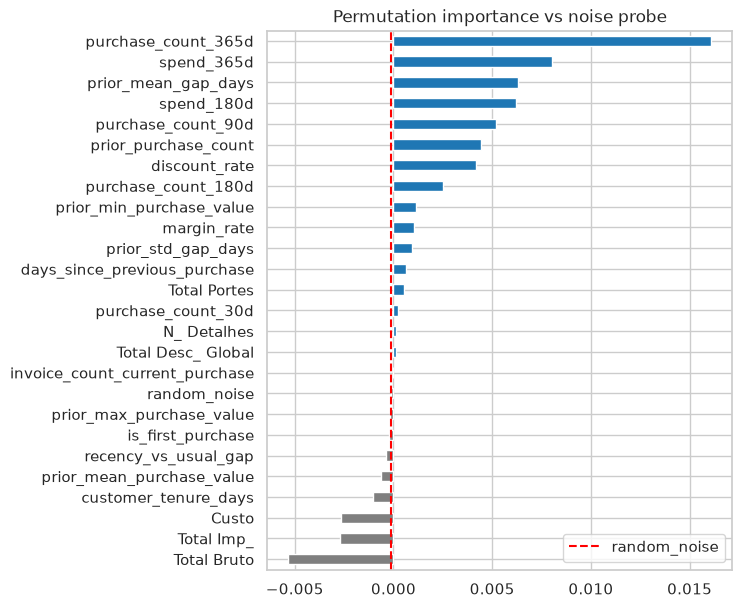

Dropped below the noise probe: ['Custo', 'Total Bruto', 'Total Imp_', 'customer_tenure_days', 'is_first_purchase', 'prior_max_purchase_value', 'prior_mean_purchase_value', 'recency_vs_usual_gap']


In [18]:
# Inner time split inside the fit part
inner_cut = fit_part[DATE].quantile(0.8)
inner_train = fit_part[fit_part[DATE] < inner_cut]
inner_val = fit_part[fit_part[DATE] >= inner_cut]

rf_selector = Pipeline([
    ("prep", make_preprocessor(after_filter, [])),
    ("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                  random_state=RANDOM_STATE, n_jobs=-1)),
])
rf_selector.fit(inner_train[after_filter], inner_train[TARGET])

perm = permutation_importance(rf_selector, inner_val[after_filter], inner_val[TARGET],
                              scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=after_filter).sort_values()
noise_level = importance["random_noise"]

importance.plot.barh(figsize=(6, 7),
                     color=np.where(importance > noise_level, "tab:blue", "tab:gray"))
plt.axvline(noise_level, color="red", linestyle="--", label="random_noise")
plt.legend(); plt.title("Permutation importance vs noise probe"); plt.show()

selected_num = [c for c in after_filter if importance[c] > noise_level and c != "random_noise"]
print("Dropped below the noise probe:", sorted(set(after_filter) - set(selected_num) - {"random_noise"}))

Output:

We remove one feature from the older fit data at a time. If the model gets worse, that feature mattered, if it didnt change, then the feature was not so useful. 

The chart:
- Each bar is one feature: the positive bars mean the model got worse when the feature was removed, so that feature is useful
- The red line is random noise. A column of pure random numbers. removing random numbers dont hurt, so its importance is about 0. it shows what "useless" looks like. This is our benchmark.
- Positive/blue bars sit above the noise, so its better than the noise, so we keep that
- Negative/grey bars sit below the noise, so its no better than the noise, so we drop them.

the value is how much the ROC-AUC gets worse/better by scrambling/keeping the feature

## 4.4 Compare feature sets

In [19]:
def inner_auc(num_cols, cat_cols):
    """Fit Logistic Regression on the inner train part, return ROC-AUC on the inner validation part."""
    model = Pipeline([
        ("prep", make_preprocessor(num_cols, cat_cols)),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE)),
    ])
    model.fit(inner_train[num_cols + cat_cols], inner_train[TARGET])
    proba = model.predict_proba(inner_val[num_cols + cat_cols])[:, 1]
    return round(roc_auc_score(inner_val[TARGET], proba), 3)

no_transport = [c for c in candidate_cat if c != "transport_method"]
comparison = pd.DataFrame({
    "features": [len(candidate_num) + len(candidate_cat), len(after_filter) + len(candidate_cat),
                 len(selected_num) + len(candidate_cat), len(selected_num) + len(no_transport)],
    "inner ROC-AUC": [inner_auc(candidate_num, candidate_cat), inner_auc(after_filter, candidate_cat),
                      inner_auc(selected_num, candidate_cat), inner_auc(selected_num, no_transport)],
}, index=["all candidates", "after redundancy filter", "after noise probe", "noise probe, no transport_method"])
comparison

,features,inner ROC-AUC
all candidates,37,0.78
after redundancy filter,30,0.78
after noise probe,21,0.80
"noise probe, no transport_method",20,0.80


In [20]:
FINAL_NUM = selected_num
FINAL_CAT = no_transport
print(f"Final feature set: {len(FINAL_NUM)} numeric + {len(FINAL_CAT)} categorical")
print("Numeric:", FINAL_NUM)
print("Categorical:", FINAL_CAT)

Final feature set: 17 numeric + 3 categorical
Numeric: ['Total Portes', 'Total Desc_ Global', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'prior_purchase_count', 'prior_min_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'purchase_count_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'discount_rate', 'margin_rate']
Categorical: ['payment_type', 'salesperson', 'document_series']


Each selection step kept or improved ROC-AUC on the inner validation, so removing features lost nothing. Dropping transport_method removes 80 levels (about 31 encoded columns) with no loss, so we keep the simpler set. Final set: 17 numeric and 3 categorical features.

why the comparison uses the inner split and not val_part:
if we picked features by checking the real validation score, the validation set would have helped build the model, and its score in section 6 would be optimistic. Val_part is only opened once, for the final evaluation.

# 5 The model

In this section we build and fit the model. All the scoring goes in the next section, so the two stay seperate. 

## 5.1 Why Logistic Regression

We use Logistic Regression as our model. 
- It is simple and interpretable. It combines the features into a score, a weighted sum, and turns that score into a probability of a repeat purchase. Each weight (coefficient) shows whether a feature raises or lowers that probability, so the model can be explained to the commercial team.
- It needs a scaled inputs, which the pipeline provides (S. 3.3)
- class_weight="balanced" gives the smaller class (0) (no reapet) the same total weight as class 1, so the model does not neglect the customers we most want to flag.

Also, the dummy model always predicts the most frequent class, so any useful model must beat it.

In [21]:
FEATURES = FINAL_NUM + FINAL_CAT                          # the final feature set from Section 4

model = Pipeline([
    ("prep", make_preprocessor(FINAL_NUM, FINAL_CAT)),     # imputation, scaling, one-hot encoding
    ("clf", LogisticRegression(class_weight="balanced",    # balance the two classes
                               max_iter=3000,              # enough iterations for the solver to finish
                               random_state=RANDOM_STATE)),
])
model.fit(fit_part[FEATURES], fit_part[TARGET])             # learns preprocessing AND weights on the fit part only

# Baseline: always predicts the most frequent class (1 = repeat)
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(fit_part[FEATURES], fit_part[TARGET])

print("Model inputs after preprocessing:",
      len(model.named_steps["prep"].get_feature_names_out()), "columns")

Model inputs after preprocessing: 35 columns


Output: 

We now got 35 columns after preprocessing, 17 numeric columns and 18 one-hot encoded columns from the 3 categoricals.

What each part does:
- Pipeline([...]):
  Chains preprocessing and the model into one object, so .fit runs both in order and .predict applies the same step to the new data.
- model.fit(fit_part...):
  The imputer learns medians, the scaler learns means, the encoder learns cateogires, and the Logistic Regression learns weights, all from the fit part only.
- max_iter=3000:
  Logistic Regression finds its weights step by step. The default of 100 steps in sometimes too few and triggers a "failed to coverge" warning.
- DummyClassifier(strategy="most_frequent"):
  Predicts "repeat" for eveyrone, which is what you'd get withno model at all. 

The model and its preprocessing are fitted together on the fit part only (5,171 purchases up to june 2023). The validation set (1,298 later purchases) has not been used by any step so far and its opened for the first time in section 6.

# 6 Model Evaluation

The model is evaluated once, on the validation set: the 1,298 most recent purchasesm which no earlier step has used.
- ROC-AUC measures how well the model ranks returning customers above non-returning ones, independent of any cut-off
- Precision and recall on class 0 matter because the non-returners are the customers the commerial team should contact.

## 6.1 Ranking quality: ROC-AUC

In [22]:
val_proba = model.predict_proba(val_part[FEATURES])[:, 1]       # predicted probability of a repeat purchase
fit_proba = model.predict_proba(fit_part[FEATURES])[:, 1]       # same on the data the model learned from

results = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(val_part[TARGET], val_proba),
                roc_auc_score(val_part[TARGET], dummy.predict_proba(val_part[FEATURES])[:, 1]),
                roc_auc_score(fit_part[TARGET], fit_proba)],
}, index=["Logistic Regression – validation", "Dummy baseline – validation",
          "Logistic Regression – fit part"]).round(3)
results

,ROC-AUC
Logistic Regression – validation,0.80
Dummy baseline – validation,0.50
Logistic Regression – fit part,0.79


Output: 

The model clearly beats the baseline (0.80 vs 0.50). The validation score is not lower than the score on the training data (0.79), so there is no sign of overfitting: the model generalises to later purchases.

The validation score is slightly hihger than the training score.

## 6.2 Decision at the 0.5 cut-off: precision, recall and cunfusion matrix.

              precision    recall  f1-score   support

           0      0.606     0.798     0.689       515
           1      0.832     0.659     0.736       783

    accuracy                          0.714      1298
   macro avg      0.719     0.729     0.712      1298
weighted avg      0.743     0.714     0.717      1298



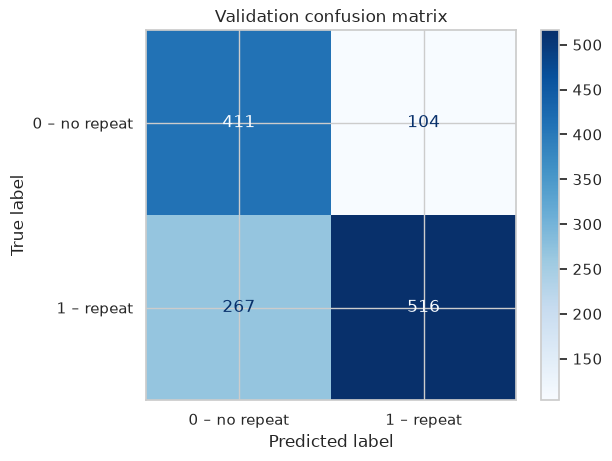

In [23]:
val_pred = model.predict(val_part[FEATURES])                     # 1 if probability ≥ 0.5, else 0

print(classification_report(val_part[TARGET], val_pred, digits=3))

ConfusionMatrixDisplay(confusion_matrix(val_part[TARGET], val_pred),
                       display_labels=["0 – no repeat", "1 – repeat"]).plot(cmap="Blues")
plt.title("Validation confusion matrix")
plt.show()

Output:

What this means in business terms: 
We trat "the customer does not return" (class 0) as the event we want to detect, since these are the custoers the commercial team should contact. 
- Correctly flagged: 411 of the 515 customers who did not return (recall for class 0 = 0.80)
- Type I error (false positive): 267 were flagged as not returning but did return. About 39% of the 678 flagged customers are false alarms (precision for class 0 = 0.61)
- Type II error (false negative): 104 customers who did not return were missed (20% for all non-returners)

For a retention campaign, a type II error is usally tthe more costly one: a lost customer means lost future revenue, while a type I error only costs an unnecessary contact. 

accuracy (0.714) is not our main metric because it hides this trade off: a dummy model that predicts "repeat" for everyone already raches 0.603 accuracy while missing every single non-returner.

## 6.3 What drives the predictions

In [24]:
# Coefficients on scaled inputs, so their sizes are comparable
coef = pd.Series(model.named_steps["clf"].coef_[0],
                 index=model.named_steps["prep"].get_feature_names_out()).sort_values()

print("Strongest positive (more likely to repeat):\n", coef.tail(5).round(2))
print("\nStrongest negative (less likely to repeat):\n", coef.head(5).round(2))

Strongest positive (more likely to repeat):
 num__prior_purchase_count                    0.33
Cat__salesperson_VLOOKUP Master 2            0.51
Cat__payment_type_Maybe Tomorrow Payment 9   0.77
num__purchase_count_90d                      1.36
num__purchase_count_365d                     1.89
dtype: float64

Strongest negative (less likely to repeat):
 num__purchase_count_180d                      -0.71
Cat__payment_type_Maybe Tomorrow Payment 10   -0.63
num__purchase_count_30d                       -0.34
Cat__salesperson_infrequent_sklearn           -0.28
Cat__salesperson_VLOOKUP Master 4             -0.21
dtype: float64


Output: 

The strongest positive drivers are purchase frequency over the last 365 days and 90 days, consistent with the EDA (Section 2.2) and the feature selection (Section 4.3). 

The negative coefficients on purchase_count_180d and purchase_count_30d should not be read as "more purchases make a customer less likely to return". The three count windows overlap and are correlated (0.7 - 0.8 below our 0.9 filter), so the model splits their joint effect across them. 

Together, more recent purchases still mean a higher repeat probability: payment type and salesperson also carry some signal, which we cannot interpret further because the categories are anonymised. 



# 7 Deployment: predictions for test-data

For the final predictions, the model is refitted on all cleaned training data (fit part and validation part together, 6,469 purchases) with exactly the same features and settings. The most recent purchases are the closest in time to test, so leaving them out would waste the most relevant information. The validation score from Section 6 remains our estimation of performance. The test data only passes through .predict: nothing is fitted on it.


In [27]:
# Same pipeline and settings as Section 5, now fitted on all of train
final_model = Pipeline([
    ("prep", make_preprocessor(FINAL_NUM, FINAL_CAT)),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE)),
])
final_model.fit(train_clean[FEATURES], train_clean[TARGET])

# Predictions: ID copied straight from test, target as 0/1
submission = pd.DataFrame({
    ID_COL: test_clean[ID_COL],
    TARGET: final_model.predict(test_clean[FEATURES]).astype(int),
})

# Checks before uploading – the notebook stops with an error if any of these fail
assert len(submission) == len(sample_submission)                    # one prediction per test row (986)
assert set(submission[ID_COL]) == set(sample_submission[ID_COL])    # exactly the same IDs
assert submission[TARGET].isin([0, 1]).all()                        # only 0 or 1

submission.to_csv("ML_Group_25_Version01.csv", index=False)   # DONT FORGET THE VERSION UPLOAD
print("Rows:", len(submission))
print(submission[TARGET].value_counts(normalize=True).round(3))
submission.head()

Rows: 986
repeat_purchase_90d
1   0.56
0   0.44
Name: proportion, dtype: float64


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,0


output:

- final model (is a new pipeline): refitting on all of train recomputes the medians, scaling and weights on all 6,469 rows
- test_clean[ID_COL]: the ID is copied unchanged from test, which is required
- .astype(int): makes sure Kagge gets 0/1 and not 0.0/1.0
- assert: each line checks one condition and stops the notebook if it's false, so a broken file cant be saved silently.
- index=false: without it, pandas writes an extra unnamed column for row numers, and Kaggle rejects the file.

All 986 test rows recieved a predicted, the IDs match sample_submission exactly, and every prediction is either 1 or 0. The model predicts a repeat purchase for 56% of test rows in line with the repeat rates seen in train (55-60%), so the predictions show no obvious shift.

# 8. Conclusion

We built a Logistic Regression model that predicts whether a customer buys again within 90 days. On the most recent 20% of the training period, which the model never saw during fitting, it reaches a ROC-AUC of 0.80, compared with 0.50 for a baseline that always predicts "repeat". At the default cut-off it identifies 80% of customers who do not return, while about 4 in 10 flagged customers are false alarms.

Purchase frequency is the strongest driver: customers with more purchases in the last 90 and 365 days are much more likely to return, while the size of the current invoice adds almost nothing. The optional clientes.csv table was not used, because its only complete attribute duplicates the tenure information already in train.

The main limitation is that performance is estimated on a single time-based split, so the score could vary with a different period. The cut-off was also left at 0.5; in practice it should be chosen from the actual cost of contacting a customer versus losing one.